# RPS冻结信号：匹配诊断与历史覆盖

## tl;dr
低位转强确认两段仍弱；RPS＋量价没有稳定增量；超跌匹配覆盖不足。核实239只研究期退市A股在当前面板和同花顺原始库均缺失，旧缓存有128只、本机原始价有其中106只，111只仍缺。应先修历史股票池，不追加调参。

## Context & Methods

### Key Assumptions
本轮是已见历史的事后机制诊断，不是新策略或未见样本外。冻结信号完全相同。调整价只作价格表现，不模拟真实成交/现金账户。主20日，5日敏感性；段末退出跨期标签截断。信号前20市场日波动率和成交额中位数各5组、同日25格、对照去掉候选、已知控制至少5只。成交额不是市值；没有行业或历史市值中性。

月均同日匹配差，3月循环块5000次重抽样、每段3主比较98.3333%区间；缺标签/无匹配计数不补零。重叠事件与数据缺口限制因果和盈利判断。其他预计算区间只作描述。

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
out = Path.cwd()
evidence = out.parent / 'exchange_evidence'
contrasts = pd.read_csv(out/'reviewed_contrasts.csv')
coverage = pd.read_csv(out/'matching_coverage.csv')
confirmation = pd.read_csv(out/'confirmation_summary.csv')
verification = json.loads((out/'verification.json').read_text(encoding='utf-8'))
terminal = json.loads((evidence/'coverage.json').read_text(encoding='utf-8'))
raw = json.loads((evidence/'configured_raw_coverage.json').read_text(encoding='utf-8'))
names = {'rps_pv': 'RPS＋量价', 'rps_only': '仅RPS', 'low_turn': '低位转强', 'low_only': '仅低位', 'oversold_confirm': '超跌＋确认', 'oversold_only': '仅超跌'}
order = ['rps_pv', 'low_turn', 'oversold_confirm']
plt.rcParams.update({'font.family':'Microsoft YaHei','axes.unicode_minus':False,'figure.dpi':120,'font.size':11})
colors = {'early':'#3565a0','late':'#bb8537'}

## Data
行情控制源为哈希已冻结的同花顺前复权面板；名单控制源是2026-10-06读取的上/深交易所终止上市快照。只做覆盖核对，名单不能当时点证券主表。完整SQL与原响应在local_evidence，原JSON/XLSX与请求回执在exchange_evidence。旧TDX缓存与配置原始日线只盘点、不混入标签。

In [2]:
display(pd.DataFrame([{'核对退市代码':terminal['window_terminal_codes'],'当前面板有记录':terminal['in_frozen_panel'],'同花顺原表有记录':terminal['with_any_raw_history'],'缓存有记录':128,'本机原始价有记录':raw['raw_present'],'两者都缺':111}]))
display(pd.DataFrame([verification])[['sampled_matched_events','passed','unmatched_points_reconciled_to_frozen_v2','maximum_original_point_difference_pp']])

,核对退市代码,当前面板有记录,同花顺原表有记录,缓存有记录,本机原始价有记录,两者都缺
0,239,0,0,128,106,111


,sampled_matched_events,passed,unmatched_points_reconciled_to_frozen_v2,maximum_original_point_difference_pp
0,224,224,True,1.007176e-07


## Results
### 1. 主20日匹配差与统计区间
均值和区间均基于月均同日差；有效事件匹配覆盖随点估计同时展示，避免把小子样本推广到全部候选。价格差不是年化、账户收益或因果效果。

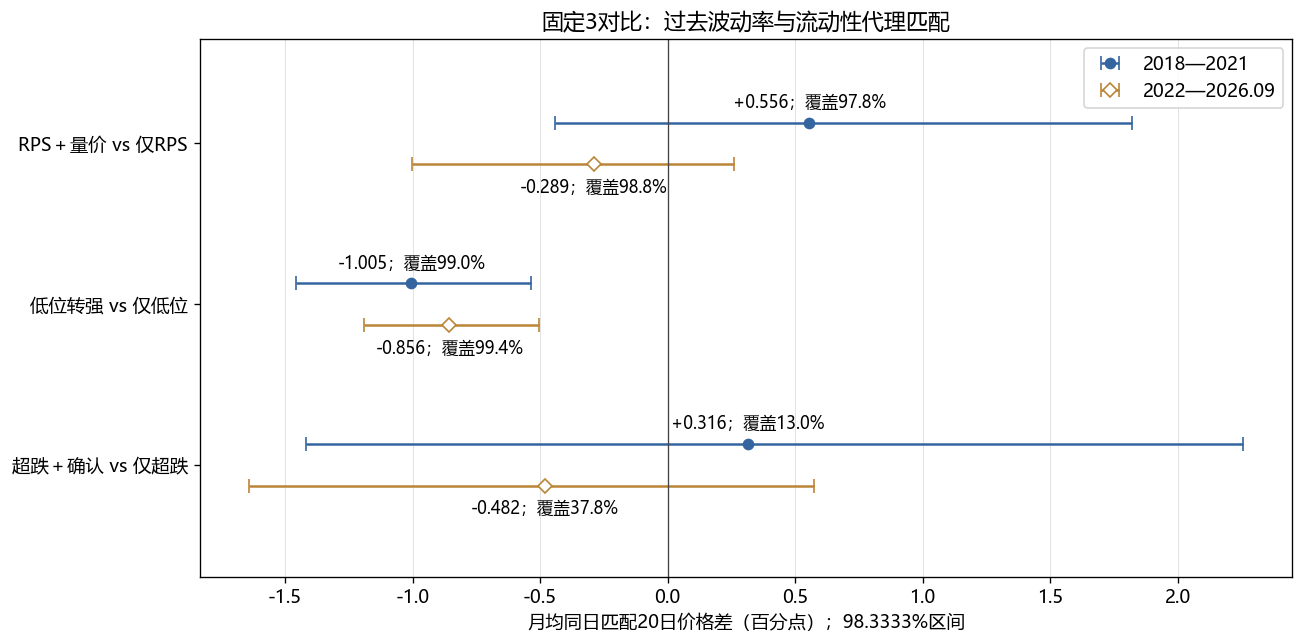

,candidate,baseline,period,mean_pp,lo_pp,hi_pp,months,paired_days,labels,matched_used_labels,valid_match_coverage_pct
0,low_turn,low_only,early,-1.005,-1.458,-0.534,48,952,62968,62316,98.965
1,oversold_confirm,oversold_only,early,0.316,-1.418,2.255,37,148,4814,625,12.983
2,rps_pv,rps_only,early,0.556,-0.441,1.822,48,836,11616,11362,97.813
3,low_turn,low_only,late,-0.856,-1.191,-0.504,56,1128,116701,115993,99.393
4,oversold_confirm,oversold_only,late,-0.482,-1.639,0.575,56,392,10979,4153,37.827
5,rps_pv,rps_only,late,-0.289,-1.001,0.258,56,1085,23001,22720,98.778


In [3]:
primary = contrasts[(contrasts.horizon==20)&(contrasts.comparison=='matched_difference')].merge(coverage[coverage.horizon==20],on=['candidate','baseline','period','horizon'],validate='one_to_one')
fig, ax = plt.subplots(figsize=(11,5.5))
for period,offset,marker,label in [('early',-.13,'o','2018—2021'),('late',.13,'D','2022—2026.09')]:
    data = primary[primary.period==period].set_index('candidate').reindex(order)
    y = np.arange(3)+offset
    ax.errorbar(data.mean_pp,y,xerr=[data.mean_pp-data.lo_pp,data.hi_pp-data.mean_pp],fmt=marker,capsize=4,color=colors[period],mfc=colors[period] if period=='early' else 'white',label=label)
    for point,yy,cov in zip(data.mean_pp,y,data.valid_match_coverage_pct):
        ax.annotate(f'{point:+.3f}；覆盖{cov:.1f}%',(point,yy),xytext=(0,-17 if period=='late' else 9),textcoords='offset points',ha='center',fontsize=10)
ax.set_yticks(range(3),[names[m]+' vs '+names[b] for m,b in zip(order,['rps_only','low_only','oversold_only'])]); ax.invert_yaxis()
ax.axvline(0,color='#444444',linewidth=.8); ax.grid(axis='x',color='#dddddd',linewidth=.5); ax.set_axisbelow(True)
ax.set_xlabel('月均同日匹配20日价格差（百分点）；98.3333%区间'); ax.set_title('固定3对比：过去波动率与流动性代理匹配')
ax.legend(loc='upper right'); ax.set_ylim(2.7,-.65); fig.tight_layout(); fig.savefig(out/'matched-intervals.png'); plt.show()
display(primary[['candidate','baseline','period','mean_pp','lo_pp','hi_pp','months','paired_days','labels','matched_used_labels','valid_match_coverage_pct']].round(3))

低位转强两段仍负、区间低于0；RPS＋量价两段区间跨0，点估计跨段变号。超跌确认匹配覆盖约13%/38%，早期只有37月、148日；宽区间与覆盖选择限制了判断。

### 2. 确认前后价格变化
仅描述已经确认的样本，先按信号日等权平均，再平均日期。这不是可实施的提前买入收益，也不是确认导致收益差的因果证明。

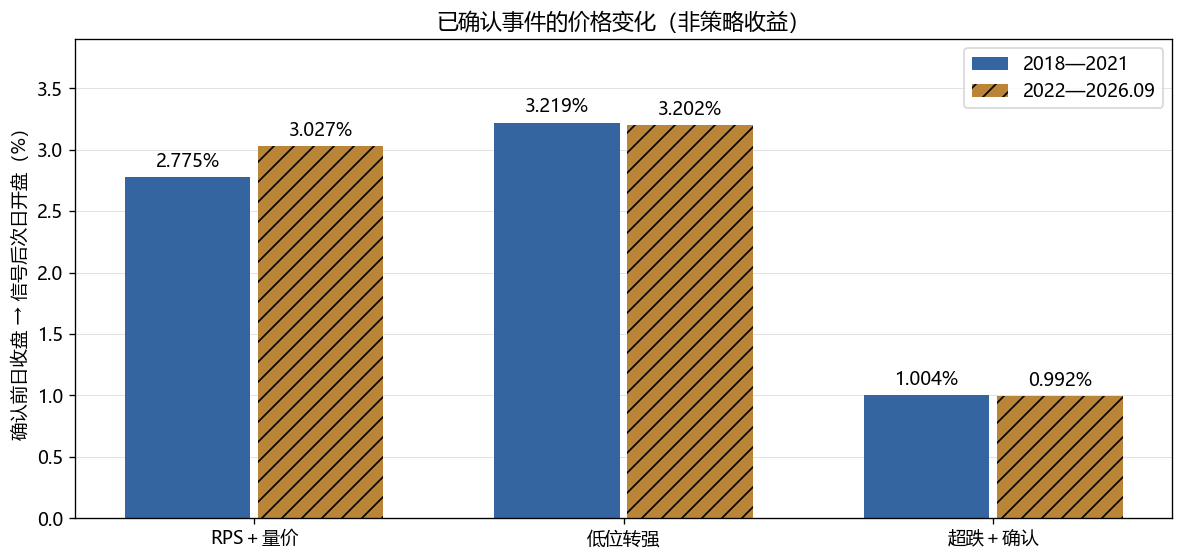

,model,period,signal_day_pct,next_open_gap_pct,total_to_next_open_pct,next_open_available
1,low_turn,early,3.413,-0.194,3.219,64244
2,oversold_confirm,early,1.086,-0.082,1.004,4943
5,rps_pv,early,2.987,-0.204,2.775,12077
7,low_turn,late,3.349,-0.145,3.202,120340
8,oversold_confirm,late,1.126,-0.134,0.992,11127
11,rps_pv,late,3.215,-0.185,3.027,23244


In [4]:
fig, ax = plt.subplots(figsize=(10,4.8))
for period,offset,label,hatch in [('early',-.18,'2018—2021',''),('late',.18,'2022—2026.09','//')]:
    data = confirmation[confirmation.period==period].set_index('model').reindex(order)
    x = np.arange(3)+offset
    bars = ax.bar(x,data.total_to_next_open_pct,width=.34,color=colors[period],label=label,hatch=hatch)
    ax.bar_label(bars,fmt='%.3f%%',padding=4)
ax.set_xticks(range(3),[names[m] for m in order]); ax.set_ylim(0,3.9)
ax.set_ylabel('确认前日收盘 → 信号后次日开盘（%）'); ax.set_title('已确认事件的价格变化（非策略收益）'); ax.legend()
ax.grid(axis='y',color='#dddddd',linewidth=.5); ax.set_axisbelow(True); fig.tight_layout(); fig.savefig(out/'confirmation-price.png'); plt.show()
display(confirmation[confirmation.model.isin(order)][['model','period','signal_day_pct','next_open_gap_pct','total_to_next_open_pct','next_open_available']].round(3))

## Takeaways
先补数，后判断盈利。239只研究期终止上市股票都缺当前同花顺历史，128只旧缓存仅是修复线索；其中106只存在本机原始价，22只只有缓存、111只两者均无，5只原始末日早于缓存。数据契约要求不复用代码的证券ID与有效期、历史ST/行业/股本、公司行动与可得时间、原始价格限制和最终处置约定。

确认日条件天然挑选上涨事件，因此约3%的确认前后涨幅不能作为昨天买入的可执行修复。补数后另版本重跑冻结规则仍是旧历史复核；不能临时改阈值、删失败年或叫独立样本外。没有实盘、券商或自动下单动作。

当前同花顺market.history入口对601258.SH、000540.SZ的2023年6月未复权历史查询均返回Unknown thscode，未取得行情；仅限两只请求的可行性结论，不说明其他来源不存在。需具备相应历史覆盖的合法数据或原始导出，不能猜补。回执：history_probe/summary.json。